# Which questions are still unanswered after 24 hours

This notebook calls the same functions as `python -m src.run_all`. The figures and numbers below are the interview brief in [REPORT.md](../REPORT.md).

The product is a developer Q&A marketplace. The decision is which new questions will still have no answer from someone else after 24 hours, and whether the composer should require a code sample.


In [1]:
import sys
from pathlib import Path

here = Path.cwd().resolve()
for candidate in [here, *here.parents]:
    if (candidate / "src" / "run_all.py").exists():
        sys.path.insert(0, str(candidate))
        break

from src.run_all import main

main()  # skips stages that already have outputs; pass force=True to recompute


Using existing /workspace/data/processed/questions.parquet


## The label and the base rate

The analysis table is built in `src/build.py`. Self-answers are excluded. Questions closed within 24 hours with no other answer are held out of the primary label. Questions posted in the last 24 hours of the dump are dropped.


Questions parsed: 1,264,216
Answers parsed:   2,014,516
Primary set:      1,255,701
24-hour answer rate: 72.4%
Eventually answered by someone else: 82.7%
Median hours to that answer: 0.35
Train through 2015-04-08T14:14:07+00:00; validation through 2016-01-28T09:48:24+00:00


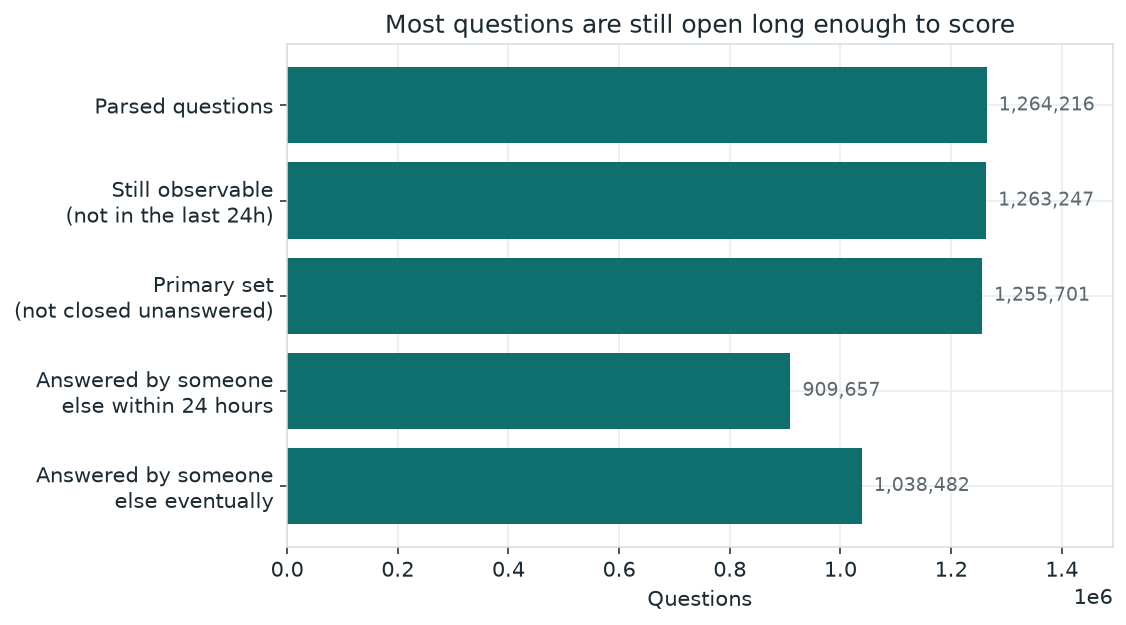

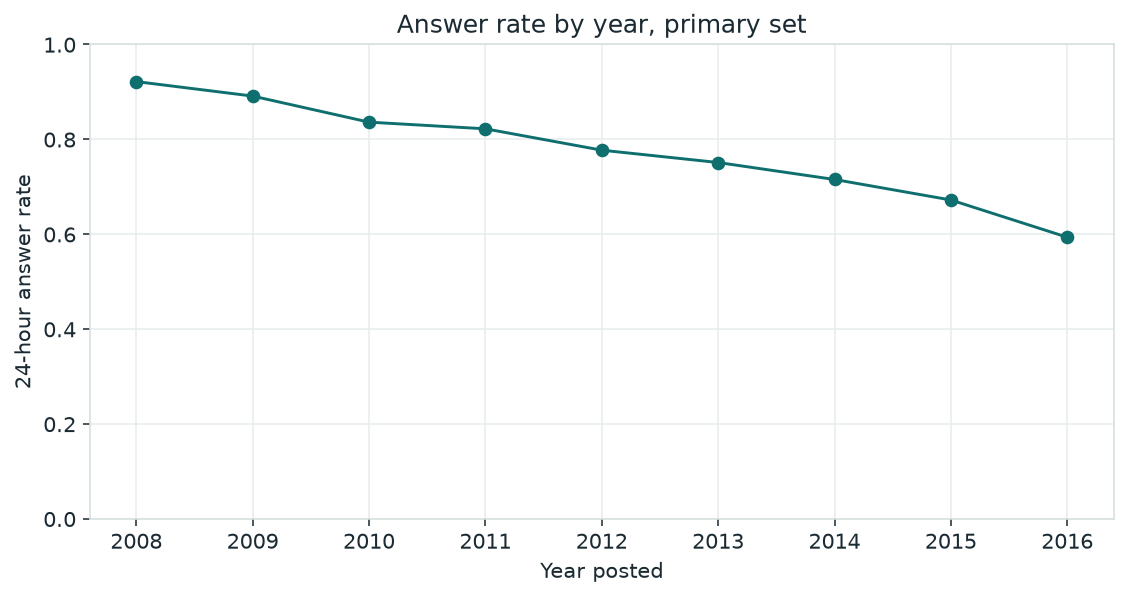

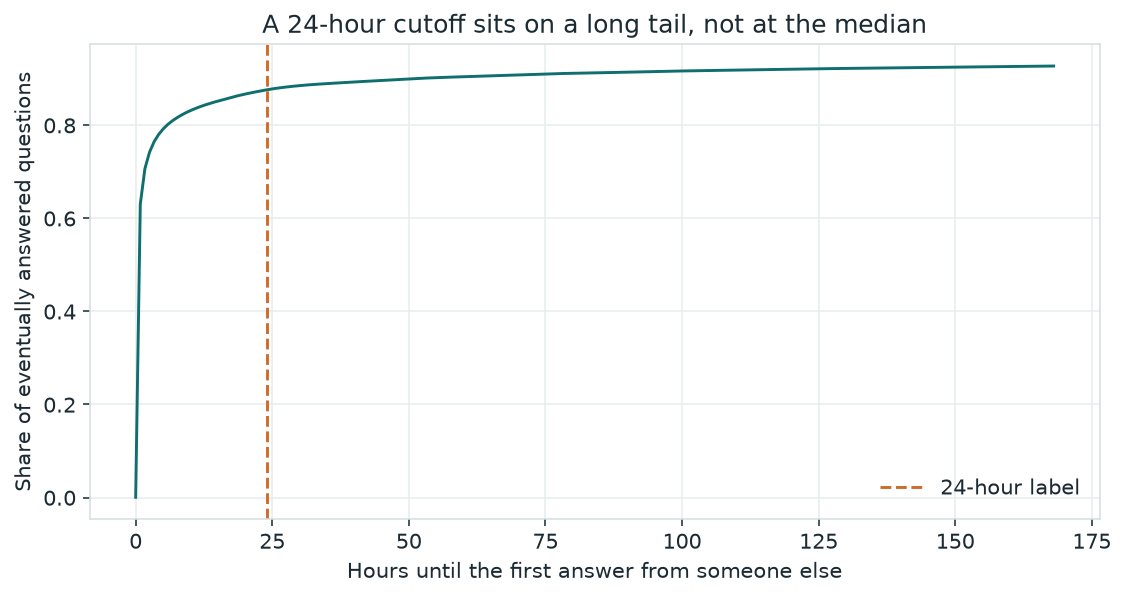

In [2]:
from IPython.display import Image, display, Markdown
from src.config import FIGURES, OUTPUTS
from src.io_utils import read_json

build = read_json(OUTPUTS / "build_summary.json")
eda = read_json(OUTPUTS / "eda_summary.json")
split = read_json(OUTPUTS / "split.json")
print(f"Questions parsed: {build['n_questions_parsed']:,}")
print(f"Answers parsed:   {build['n_answers_parsed']:,}")
print(f"Primary set:      {build['n_primary']:,}")
print(f"24-hour answer rate: {eda['answer_rate_24h']:.1%}")
print(f"Eventually answered by someone else: {eda['eventual_answer_rate']:.1%}")
print(f"Median hours to that answer: {eda['median_hours_to_answer']:.2f}")
print(f"Train through {split['train_end']}; validation through {split['val_end']}")
display(Image(filename=str(FIGURES / "01_funnel.png")))
display(Image(filename=str(FIGURES / "02_answer_rate_by_year.png")))
display(Image(filename=str(FIGURES / "06_time_to_answer.png")))


## Three pre-specified tests

Estimated on the training window only, with tag family and year held fixed. A 2 percentage-point gap is the practical bar. The p-values are tiny because the sample is large; the interval is the result.


Code block
  adjusted risk difference +3.514%  CI +3.320% to +3.707%
  decision: larger than the 2 point bar
Weekend minus weekday
  adjusted risk difference +0.600%  CI +0.371% to +0.829%
  decision: in the opposite direction
Title length
  likelihood-ratio statistic 201.5 on 1 df
  bin gap 12.5%  U-shape claimed by the curve: False
  decision: non-linear and the bin gap clears 2 points
        1–20  82.8%
       21–40  79.6%
       41–60  76.6%
       61–80  73.7%
      81–100  71.6%
        101+  70.3%


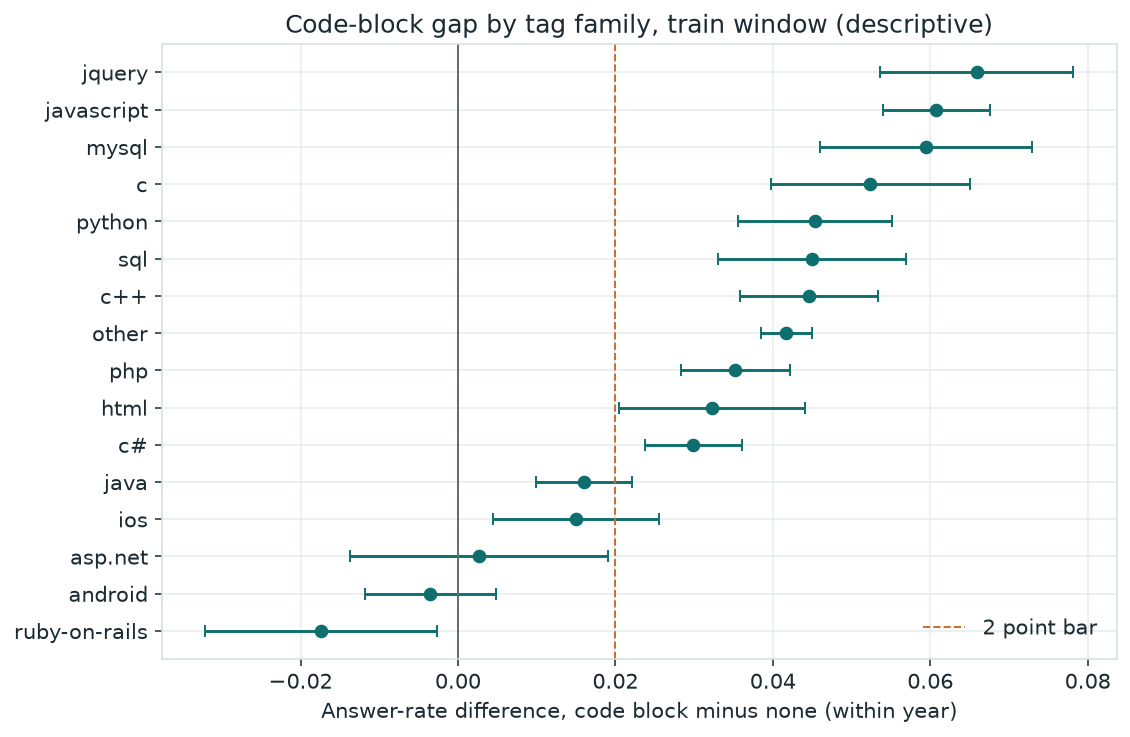

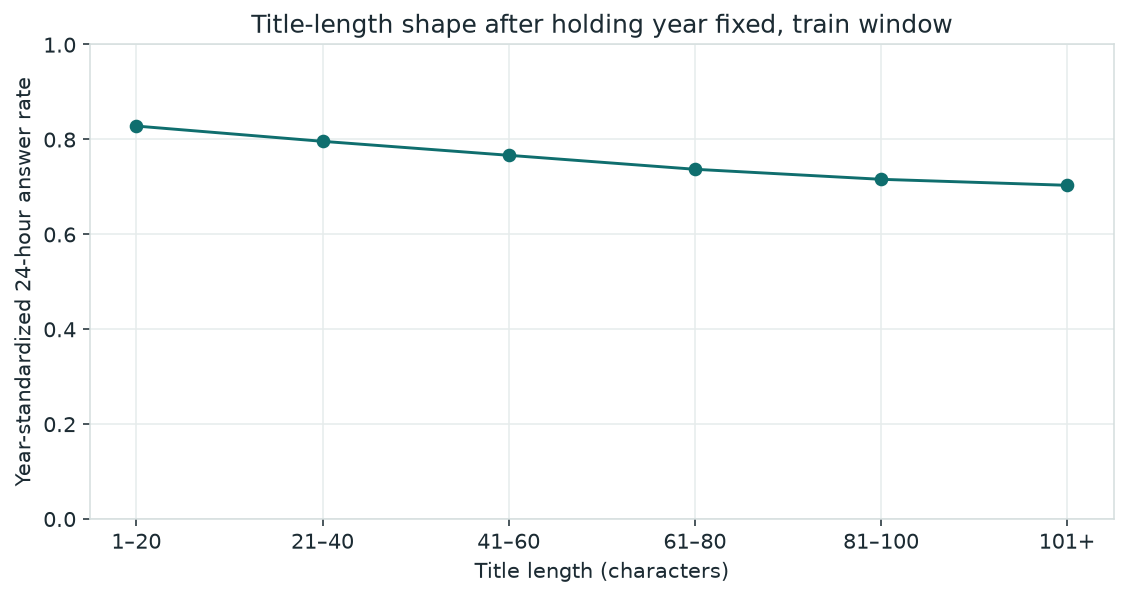

In [3]:
hyp = read_json(OUTPUTS / "hypotheses.json")
code_rd = hyp["code_block"]
weekend = hyp["weekend"]
title = hyp["title_length"]
print("Code block")
print(f"  adjusted risk difference {code_rd['rd']:+.3%}  CI {code_rd['ci95'][0]:+.3%} to {code_rd['ci95'][1]:+.3%}")
print(f"  decision: {code_rd['decision']}")
print("Weekend minus weekday")
print(f"  adjusted risk difference {weekend['rd']:+.3%}  CI {weekend['ci95'][0]:+.3%} to {weekend['ci95'][1]:+.3%}")
print(f"  decision: {weekend['decision']}")
print("Title length")
print(f"  likelihood-ratio statistic {title['lr_stat']:.1f} on {title['df']} df")
print(f"  bin gap {title['bin_rate_range']:.1%}  U-shape claimed by the curve: {title['shape_matches_u']}")
print(f"  decision: {title['decision']}")
for label, rate in title["year_standardized_bin_rates"].items():
    print(f"    {label:>8}  {rate:.1%}")
display(Image(filename=str(FIGURES / "08_code_effect_by_family.png")))
display(Image(filename=str(FIGURES / "10_title_length_adjusted.png")))


## Models

The positive class is still unanswered at 24 hours. The model is chosen on validation precision in the top 5%, then scored once on the test window. Algorithm intuition is in the report: logistic regression is the explainable baseline, the forest and the boosting model are the variance-versus-bias check, and the title-word model asks whether words beat structure.


Selected on validation: title_tfidf
title_tfidf beats the business rule by at least 1 point of precision at 5% on the validation window.
model                 val P@5  test P@5  test AUC  test Brier
base_rate               0.347     0.411     0.500       0.273
business_rule           0.466     0.562     0.546       0.392
logistic                0.518     0.590     0.637       0.251
random_forest           0.535     0.602     0.639       0.245
gradient_boosting       0.538     0.608     0.641       0.250
title_tfidf             0.643     0.695     0.699       0.218


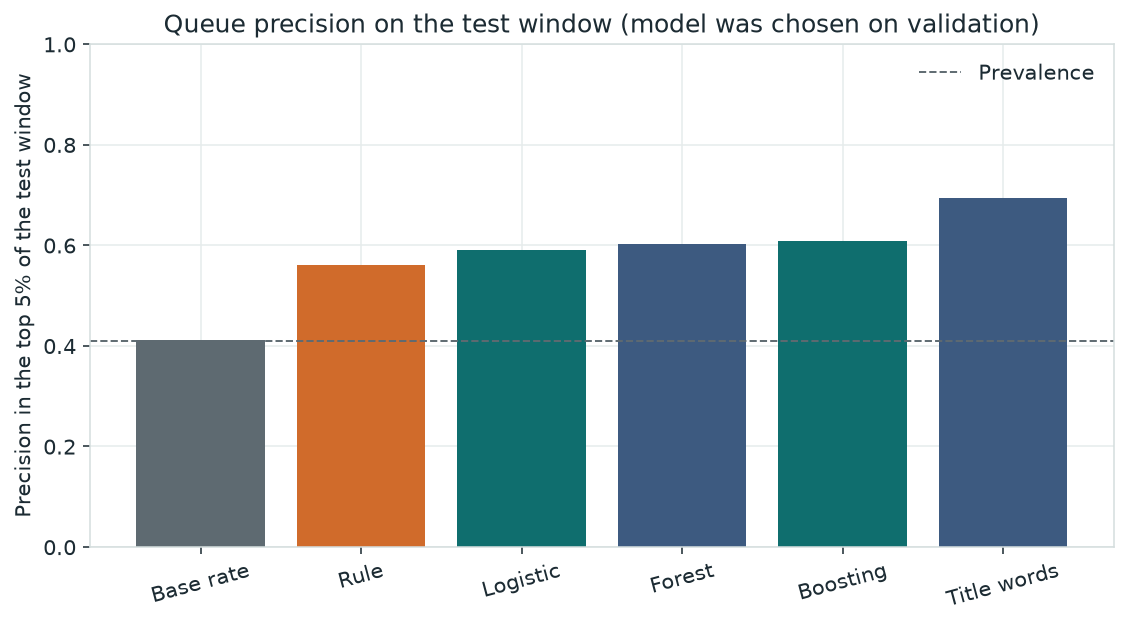

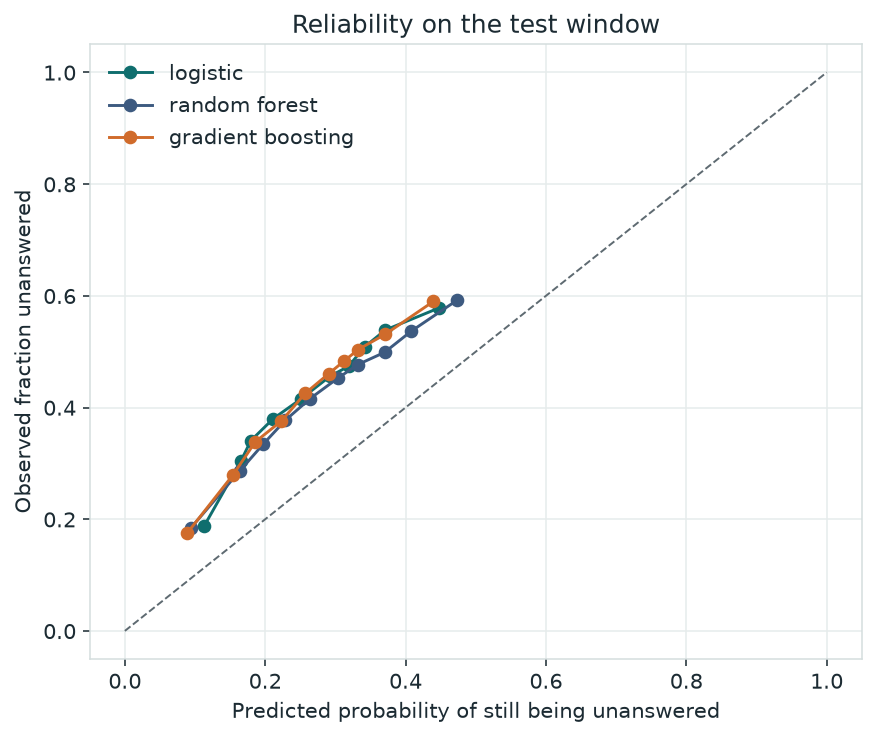

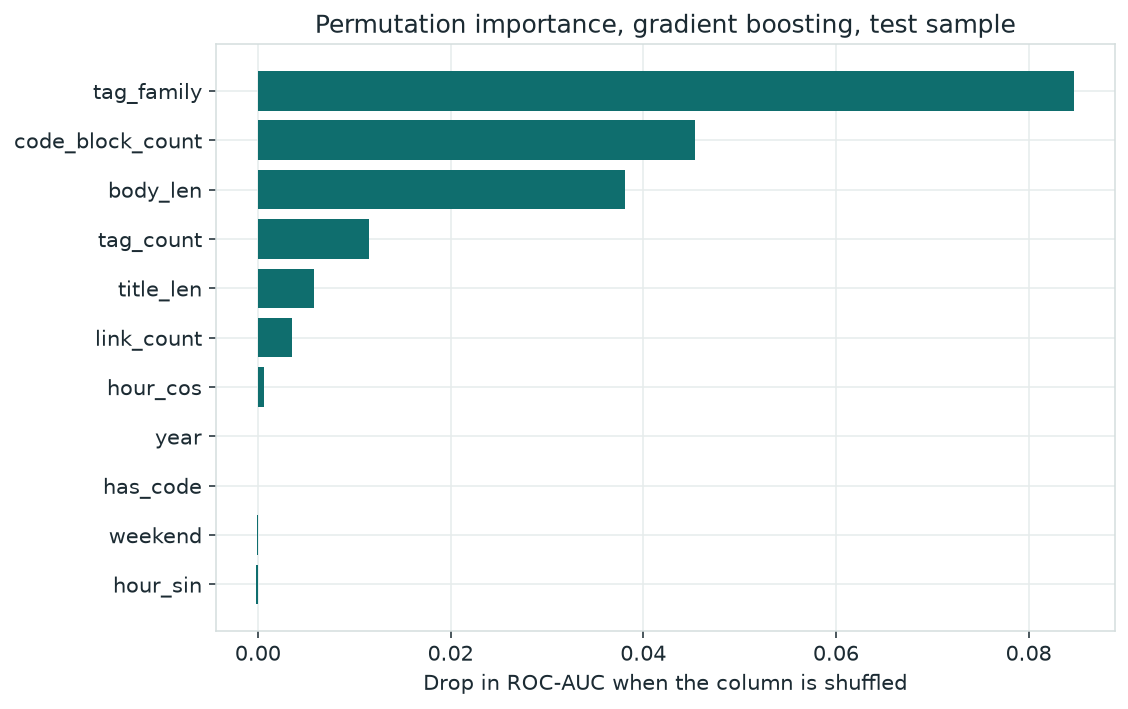

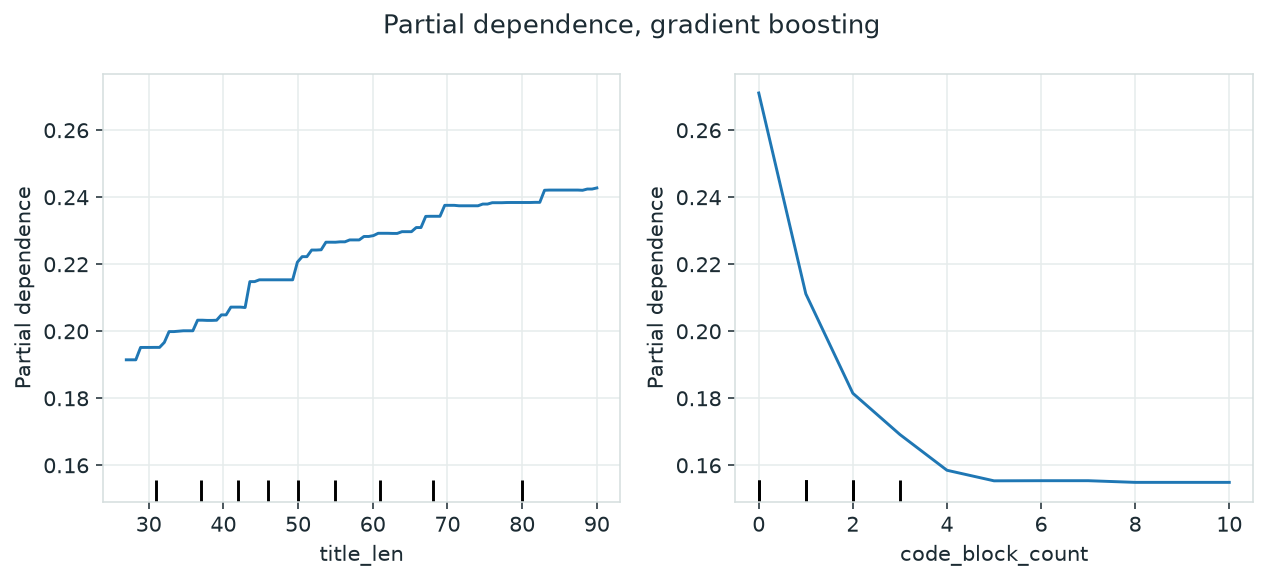

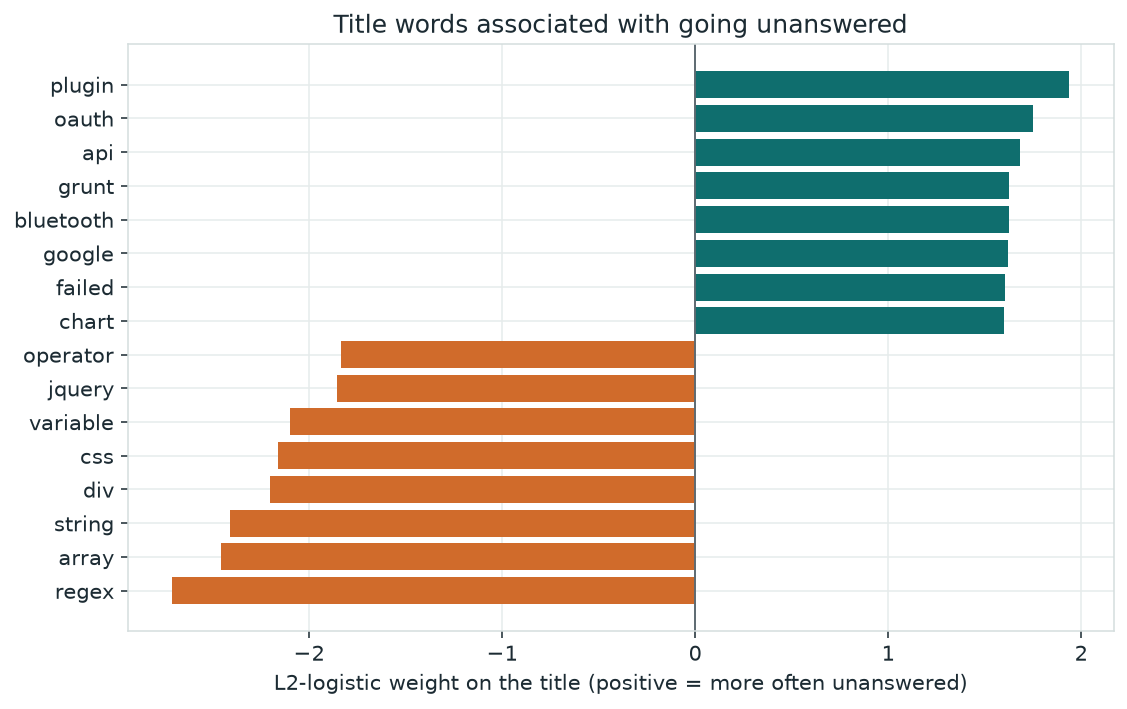

In [4]:
metrics = read_json(OUTPUTS / "model_metrics.json")
print(f"Selected on validation: {metrics['selected_model']}")
print(metrics["ship_reason"])
print(f"{'model':<20} {'val P@5':>8} {'test P@5':>9} {'test AUC':>9} {'test Brier':>11}")
for name, row in metrics["metrics"].items():
    print(f"{name:<20} {row['val']['precision_at_5pct']:8.3f} {row['test']['precision_at_5pct']:9.3f} {row['test']['roc_auc']:9.3f} {row['test']['brier']:11.3f}")
display(Image(filename=str(FIGURES / "11_precision_at_capacity.png")))
display(Image(filename=str(FIGURES / "12_calibration.png")))
display(Image(filename=str(FIGURES / "13_importance.png")))
display(Image(filename=str(FIGURES / "14_partial_dependence.png")))
display(Image(filename=str(FIGURES / "15_title_words.png")))


## The experiment this file cannot run

The code-block gap is an association. `src/experiment.py` sizes a user-randomized composer test and a guardrail on posting volume.


In [5]:
exp = read_json(OUTPUTS / "experiment.json")
print("Tags:", ", ".join(exp["tag_families"]))
print(f"Recent baseline answer rate: {exp['baseline_answer_rate_test_window']:.1%}")
print(f"Questions per arm, with clustering: {exp['questions_per_arm_with_design_effect']:,.0f}")
print(f"ICC: {exp['icc_train_window']['icc']:.3f}   design effect: {exp['design_effect_used']:.2f}")
print(f"Recommended duration: {exp['recommended_duration_days']:.0f} days")
print(exp["guardrail"]["rule"])


Tags: javascript, java, c#, php, android
Recent baseline answer rate: 62.2%
Questions per arm, with clustering: 17,768
ICC: 0.100   design effect: 1.95
Recommended duration: 14 days
Do not ship the wizard if the treatment arm posts more than 5% fewer questions per user and the 95% interval for that drop excludes zero.
